# EgyptOra Data Cleaning Notebook

Data preparation and enrichment workflow.

## 1) Import Libraries

Main libraries used:
- pandas for data handling
- numpy for processing
- matplotlib for visualization

In [1]:

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

## 2) Load Data Files

Read source files and final datasets for comparison.

In [2]:

old_file = Path("Egyptora_Free_Verified_Data (1).xlsm")
new_file = Path("final data.xlsx")

if not old_file.exists():
    old_file = Path("/mnt/data/Egyptora_Free_Verified_Data (1).xlsm")

if not new_file.exists():
    new_file = Path("/mnt/data/final data.xlsx")

old_book = pd.read_excel(old_file, sheet_name=None)
new_book = pd.read_excel(new_file, sheet_name=None)

print("Old sheets:", len(old_book))
print(list(old_book.keys()))

print("\nFinal sheets:", len(new_book))
print(list(new_book.keys()))

Old sheets: 14
['Tourism Annual', 'MOTA Hotels', 'MOTA Archaeology', 'MOTA Inventory', 'MOTA Museums', 'Destinations', 'NASA Climate', 'UNESCO', 'Wikimedia Interest', 'Wikimedia Coverage', 'Wikimedia Common', 'Attraction Reference', 'Attraction Linked', 'Governorates']

Final sheets: 14
['Tourism annual', 'MOTA Archaeology', 'MOTA Museums', 'Destinations', 'NASA Climate', 'UNESCO', 'Wikimedia Interest', 'Wikimedia Coverage', 'Wikimedia Common', 'Attraction Reference', 'Attraction Linked', 'Governorates', 'moto hotel', 'moto inventory']


## 3) Data Cleaning Functions

Created reusable functions for:
- Removing empty rows
- Cleaning text values
- Detecting data issues

In [3]:

arabic_pattern = re.compile(r"[\u0600-\u06FF]")

def basic_clean(df):
    df = df.copy()

    df = df.dropna(how="all")
    df = df.dropna(axis=1, how="all")

    text_columns = df.select_dtypes(include="object").columns

    for col in text_columns:
        df[col] = df[col].apply(
            lambda x: " ".join(x.replace("\xa0", " ").split())
            if isinstance(x, str) else x
        )

    return df


def count_arabic_cells(df):
    count = 0

    for value in df.to_numpy().ravel():
        if pd.notna(value) and arabic_pattern.search(str(value)):
            count += 1

    return count

## 4) Before vs After Comparison

Compare:
- Rows count
- Data quality
- Text consistency

In [4]:

def book_summary(book):
    total_rows = sum(len(df) for df in book.values())
    arabic_cells = sum(count_arabic_cells(df) for df in book.values())
    missing_cells = sum(int(df.isna().sum().sum()) for df in book.values())
    duplicate_rows = sum(int(df.duplicated().sum()) for df in book.values())

    return {
        "Total Data Rows": total_rows,
        "Arabic Cells": arabic_cells,
        "Missing Cells": missing_cells,
        "Exact Duplicate Rows": duplicate_rows,
    }


summary = pd.DataFrame(
    [book_summary(old_book), book_summary(new_book)],
    index=["Before Cleaning", "After Cleaning"]
)

display(summary)

,Total Data Rows,Arabic Cells,Missing Cells,Exact Duplicate Rows
Before Cleaning,11839,13666,4968,0
After Cleaning,11813,0,0,3


## Cleaning Results

Validated improvements after applying cleaning steps.

## 5) Sheet Comparison

Matched old and final sheets before processing.

In [5]:

sheet_map = {
    "Tourism Annual": "Tourism annual",
    "MOTA Hotels": "moto hotel",
    "MOTA Archaeology": "MOTA Archaeology",
    "MOTA Inventory": "moto inventory",
    "MOTA Museums": "MOTA Museums",
    "Destinations": "Destinations",
    "NASA Climate": "NASA Climate",
    "UNESCO": "UNESCO",
    "Wikimedia Interest": "Wikimedia Interest",
    "Wikimedia Coverage": "Wikimedia Coverage",
    "Wikimedia Common": "Wikimedia Common",
    "Attraction Reference": "Attraction Reference",
    "Attraction Linked": "Attraction Linked",
    "Governorates": "Governorates",
}

rows = []

for old_name, new_name in sheet_map.items():
    old_df = old_book[old_name]
    new_df = new_book[new_name]

    rows.append({
        "Sheet": old_name,
        "Rows Before": len(old_df),
        "Rows After": len(new_df),
        "Columns Before": old_df.shape[1],
        "Columns After": new_df.shape[1],
        "Arabic Before": count_arabic_cells(old_df),
        "Arabic After": count_arabic_cells(new_df),
    })

sheet_comparison = pd.DataFrame(rows)
display(sheet_comparison)

,Sheet,Rows Before,Rows After,Columns Before,Columns After,Arabic Before,Arabic After
0,Tourism Annual,57,31,12,3,2,0
1,MOTA Hotels,915,915,15,5,4567,0
2,MOTA Archaeology,154,154,18,4,770,0
3,MOTA Inventory,89,89,9,4,178,0
4,MOTA Museums,31,31,18,5,155,0
5,Destinations,38,38,15,8,76,0
6,NASA Climate,3192,3192,27,19,6384,0
7,UNESCO,7,7,10,6,0,0
8,Wikimedia Interest,4854,4854,11,6,0,0
9,Wikimedia Coverage,56,56,13,7,0,0


# Cleaning Steps

## 6) Text Cleaning

Standardized text formatting and removed inconsistencies.

In [6]:

arch_old = old_book["MOTA Archaeology"].copy()

example = arch_old[["site_name_ar", "site_name_en_or_description"]].head(5).copy()

for col in example.columns:
    example[col] = example[col].apply(
        lambda x: " ".join(str(x).replace("\xa0", " ").split())
        if pd.notna(x) else x
    )

display(example)

,site_name_ar,site_name_en_or_description
0,منزل زينب خاتون,شارع الأزهر، الدرب الأحمر
1,منزل جمال الدين الذهبي,شارع المعز، الغورية
2,دير الأنبا بولا,الزعفرانه، البحر الأحمر
3,دير الأنبا أنطونيوس,الزعفرانه، البحر الأحمر
4,قلعة القصير,مدينة القصير، البحر الأحمر


## 7) Governorate Mapping

Converted Arabic governorate names into English values.

In [7]:

governorate_map = {
    "القاهرة": "Cairo",
    "الجيزة": "Giza",
    "القليوبية": "Qalyubia",
    "الأسكندرية": "Alexandria",
    "الإسكندرية": "Alexandria",
    "البحيرة": "Beheira",
    "كفر الشيخ": "Kafr El Sheikh",
    "الغربية": "Gharbia",
    "المنوفية": "Monufia",
    "الدقهلية": "Dakahlia",
    "دمياط": "Damietta",
    "بورسعيد": "Port Said",
    "الإسماعيلية": "Ismailia",
    "السويس": "Suez",
    "الشرقية": "Sharqia",
    "شمال سيناء": "North Sinai",
    "جنوب سيناء": "South Sinai",
    "البحر الأحمر": "Red Sea",
    "الفيوم": "Fayoum",
    "بني سويف": "Beni Suef",
    "المنيا": "Minya",
    "أسيوط": "Assiut",
    "سوهاج": "Sohag",
    "قنا": "Qena",
    "الأقصر": "Luxor",
    "أسوان": "Aswan",
    "الوادي الجديد": "New Valley",
    "مطروح": "Matrouh",
}

demo = old_book["Governorates"][
    ["governorate_en", "governorate_ar"]
].copy()

demo["governorate_en_alt"] = (
    demo["governorate_ar"]
    .map(governorate_map)
    .fillna(demo["governorate_en"])
)

display(demo.head(10))

,governorate_en,governorate_ar,governorate_en_alt
0,Cairo,القاهرة,Cairo
1,Giza,الجيزة,Giza
2,Qalyubia,القليوبية,Qalyubia
3,Alexandria,الإسكندرية,Alexandria
4,Beheira,البحيرة,Beheira
5,Kafr El Sheikh,كفر الشيخ,Kafr El Sheikh
6,Gharbia,الغربية,Gharbia
7,Monufia,المنوفية,Monufia
8,Dakahlia,الدقهلية,Dakahlia
9,Damietta,دمياط,Damietta


- `site_name_ar`
- `site_name_en_or_description`
- `destination_ar`
- `name_ar`
- `city_ar`



- `site_name_ar` → `site_name_en`
- `site_name_en_or_description` → `address_en`
- `destination_ar` → `destination_en_alt`
- `name_ar` → `name_en_alt`
- `governorate_ar` → `governorate_en_alt`

In [8]:

before = old_book["MOTA Archaeology"][
    ["site_name_ar", "site_name_en_or_description", "governorate_ar"]
].head(8)

after = new_book["MOTA Archaeology"][
    ["site_name_en", "address_en", "governorate_en_alt"]
].head(8)

print("BEFORE")
display(before)

print("AFTER")
display(after)

BEFORE


,site_name_ar,site_name_en_or_description,governorate_ar
0,منزل زينب خاتون,شارع الأزهر، الدرب الأحمر,القاهرة
1,منزل جمال الدين الذهبي,شارع المعز، الغورية,القاهرة
2,دير الأنبا بولا,الزعفرانه، البحر الأحمر,البحر الأحمر
3,دير الأنبا أنطونيوس,الزعفرانه، البحر الأحمر,البحر الأحمر
4,قلعة القصير,مدينة القصير، البحر الأحمر,البحر الأحمر
5,قلعة صلاح الدين,جزيرة فرعون، طابا,جنوب سيناء
6,دير سانت كاترين,الوادي المقدس، مدينة سانت كاترين,جنوب سيناء
7,منطقة آثار تل بسطا,قرية النحال، الزقازيق,الشرقية


AFTER


,site_name_en,address_en,governorate_en_alt
0,Zainab Khatoun House,"Al-Azhar Street, Al-Darb al-Ahmar",Cairo
1,Gamal al-Din al-Dhahabi House,"Al-Muizz Street, Al-Ghuriya",Cairo
2,Monastery of Saint Paul,"Zafarana, Red Sea",Red Sea
3,Monastery of Saint Anthony,"Zafarana, Red Sea",Red Sea
4,El Quseir Fortress,"City El Quseir, Red Sea",Red Sea
5,Salah al-Din Castle,"Island Pharaoh, Taba",South Sinai
6,Saint Catherine's Monastery,"Sacred Valley, City Saint Catherine",South Sinai
7,Tell Basta Archaeological Site,"Village Al-Nahhal, Zagazig",Sharqia


- Source URLs
- Download timestamps
- QA notes
- Geography QA status
- Technical metadata

In [9]:

arch_keep = [
    "site_name_en",
    "address_en",
    "governorate_en",
    "governorate_en_alt",
]

arch_final = new_book["MOTA Archaeology"][arch_keep]

print("Final analytical columns:")
print(list(arch_final.columns))
print("Shape:", arch_final.shape)

display(arch_final.head())

Final analytical columns:
['site_name_en', 'address_en', 'governorate_en', 'governorate_en_alt']
Shape: (154, 4)


,site_name_en,address_en,governorate_en,governorate_en_alt
0,Zainab Khatoun House,"Al-Azhar Street, Al-Darb al-Ahmar",Cairo,Cairo
1,Gamal al-Din al-Dhahabi House,"Al-Muizz Street, Al-Ghuriya",Cairo,Cairo
2,Monastery of Saint Paul,"Zafarana, Red Sea",Red Sea,Red Sea
3,Monastery of Saint Anthony,"Zafarana, Red Sea",Red Sea,Red Sea
4,El Quseir Fortress,"City El Quseir, Red Sea",Red Sea,Red Sea


```python
df["name_en_alt"] = df["name_en_alt"].fillna(df["name_en"])
```


### C) Enrichment

- Hotel ratings
- Wikidata IDs
- Recent tourism receipts

In [10]:

ref = new_book["Attraction Reference"].copy()

ref["name_en_alt"] = ref["name_en_alt"].fillna(ref["name_en"])
ref["governorate_en_alt"] = ref["governorate_en_alt"].fillna(
    ref["governorate_en"]
)

print("Missing name_en_alt:", ref["name_en_alt"].isna().sum())
print("Missing governorate_en_alt:", ref["governorate_en_alt"].isna().sum())

Missing name_en_alt: 0
Missing governorate_en_alt: 0


- `official_classification_stars`.


1. `Hotel Name`
2. `Governorate`
3. `Governorate (Translated)`
4. `City`
5. `Rate`

In [11]:

hotels_old = old_book["MOTA Hotels"]
hotels_final = new_book["moto hotel"]

official_rate = pd.to_numeric(
    hotels_old["official_classification_stars"],
    errors="coerce"
)

final_rate = pd.to_numeric(
    hotels_final["Rate"],
    errors="coerce"
)

official_mask = official_rate.notna()

official_count = int(official_mask.sum())
estimated_count = int((~official_mask).sum())

official_preserved = (
    official_rate[official_mask].astype(int).to_numpy()
    == final_rate[official_mask].astype(int).to_numpy()
).all()

print("Total hotels:", len(hotels_final))
print("Official ratings preserved:", official_count)
print("Logical estimates added:", estimated_count)
print("Were all official ratings preserved?", official_preserved)
print("Final missing ratings:", final_rate.isna().sum())
print("Final rating range:", int(final_rate.min()), "to", int(final_rate.max()))

Total hotels: 915
Official ratings preserved: 818
Logical estimates added: 97
Were all official ratings preserved? True
Final missing ratings: 0
Final rating range: 1 to 5


In [12]:

hotel_before = hotels_old[
    [
        "property_name_en",
        "governorate_en",
        "city_ar",
        "official_classification_stars",
    ]
].head(15)

hotel_after = hotels_final.head(15)

print("BEFORE")
display(hotel_before)

print("AFTER")
display(hotel_after)

BEFORE


,property_name_en,governorate_en,city_ar,official_classification_stars
0,marsher bell,Cairo,القاهرة,NaN
1,sun rise,South Sinai,شرم الشيخ,NaN
2,sun rise angom resort,Red Sea,مرسي علم,NaN
3,AGHORMI,Matrouh,مرسي مطروح,NaN
4,STAR,South Sinai,شرم الشيخ,NaN
5,AMARA,Red Sea,مرسي علم,NaN
6,HABI,Aswan,اسوان,NaN
7,Amarina jannah Rsort & Aqua Park MarsaAlam,Red Sea,مرسي علم,NaN
8,Daghash land hotel,South Sinai,رأس سدر,NaN
9,Regency Hotel,Giza,الجيزة,NaN


AFTER


,Hotel Name,Governorate,Governorate (Translated),City,Rate
0,marsher bell,Cairo,Cairo,Cairo,3
1,sun rise,South Sinai,South Sinai,Sharm El Sheikh,3
2,sun rise angom resort,Red Sea,Red Sea,Marsa Alam,4
3,AGHORMI,Matrouh,Matrouh,Marsa Matrouh,2
4,STAR,South Sinai,South Sinai,Sharm El Sheikh,2
5,AMARA,Red Sea,Red Sea,Marsa Alam,2
6,HABI,Aswan,Aswan,Aswan,3
7,Amarina jannah Rsort & Aqua Park MarsaAlam,Red Sea,Red Sea,Marsa Alam,4
8,Daghash land hotel,South Sinai,South Sinai,Ras Sudr,3
9,Regency Hotel,Giza,Giza,Giza,3


### Missing stars

In [13]:

inventory_old = old_book["MOTA Inventory"]
inventory_final = new_book["moto inventory"]

old_stars = pd.to_numeric(
    inventory_old["official_classification_stars"],
    errors="coerce"
)

new_stars = pd.to_numeric(
    inventory_final["classification_stars"],
    errors="coerce"
)

known_mask = old_stars.notna()

print("Official values preserved:", int(known_mask.sum()))
print("Missing values completed:", int((~known_mask).sum()))

print(
    "All original known star values unchanged:",
    (
        old_stars[known_mask].astype(int).to_numpy()
        == new_stars[known_mask].astype(int).to_numpy()
    ).all()
)

display(inventory_final.head(10))

Official values preserved: 70
Missing values completed: 19
All original known star values unchanged: True


,governorate_en,governorate_translated,classification_stars,official_directory_properties
0,Alexandria,Alexandria,1,7
1,Alexandria,Alexandria,2,10
2,Alexandria,Alexandria,3,8
3,Alexandria,Alexandria,4,6
4,Alexandria,Alexandria,5,9
5,Alexandria,Alexandria,3,3
6,Aswan,Aswan,1,4
7,Aswan,Aswan,2,5
8,Aswan,Aswan,3,2
9,Aswan,Aswan,4,4


| year | metric_code | value |
|---|---|---|
| 1995 | international_arrivals | ... |
| 1995 | tourism_receipts_usd | ... |



| year | international_arrivals | tourism_receipts_usd |
|---|---|---|

In [14]:

tourism_old = old_book["Tourism Annual"]

tourism_wide = (
    tourism_old
    .pivot(index="year", columns="metric_code", values="value")
    .reset_index()
)

tourism_wide.columns.name = None

display(tourism_wide.head())

print("Rows before pivot:", len(tourism_old))
print("Rows after pivot:", len(tourism_wide))

,year,international_arrivals,tourism_receipts_usd
0,1995,3133000.0,2.954000e+09
1,1996,3896000.0,3.583000e+09
2,1997,3961000.0,4.046000e+09
3,1998,3454000.0,2.942000e+09
4,1999,4797000.0,4.361000e+09


Rows before pivot: 57
Rows after pivot: 31


In [15]:

tourism_final = new_book["Tourism annual"]

check = tourism_wide.merge(
    tourism_final,
    on="year",
    suffixes=("_old", "_final")
)

for metric in ["international_arrivals", "tourism_receipts_usd"]:
    old_values = pd.to_numeric(
        check[f"{metric}_old"],
        errors="coerce"
    )

    final_values = pd.to_numeric(
        check[f"{metric}_final"],
        errors="coerce"
    )

    available_before = old_values.notna()

    preserved = (
        old_values[available_before].to_numpy()
        == final_values[available_before].to_numpy()
    ).all()

    added = int(
        (old_values.isna() & final_values.notna()).sum()
    )

    print(metric)
    print("  Existing values preserved:", preserved)
    print("  New values added:", added)

international_arrivals
  Existing values preserved: True
  New values added: 0
tourism_receipts_usd
  Existing values preserved: True
  New values added: 5


# 14) Attraction Reference — Wikidata Enrichment





- Original value
- Found after research
- Not found after research

In [16]:

attraction_old = old_book["Attraction Reference"]
attraction_final = new_book["Attraction Reference"]

print(
    "Missing Wikidata before:",
    attraction_old["wikidata"].isna().sum()
)

print("\nResearch status after:")
display(
    attraction_final["wikidata_research_status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Rows")
)

Missing Wikidata before: 72

Research status after:


,Status,Rows
0,ORIGINAL_VALUE,443
1,NOT_FOUND_AFTER_SEARCH,58
2,FOUND_AFTER_SEARCH,14


In [17]:

verified_wikidata = {
    "Abu Sir": "Q336098",
    "Amarna": "Q5736",
    "Dahshur": "Q685414",
    "Bayt Al-Suhaymi": "Q3280142",
    "Hurghada Grand Aquarium": "Q28419476",
}

for place, qid in verified_wikidata.items():
    print(place, "->", qid)

Abu Sir -> Q336098
Amarna -> Q5736
Dahshur -> Q685414
Bayt Al-Suhaymi -> Q3280142
Hurghada Grand Aquarium -> Q28419476


- `UNESCO`
- `Wikimedia Interest`
- `Wikimedia Coverage`
- `Wikimedia Common`

In [18]:

for sheet in [
    "UNESCO",
    "Wikimedia Interest",
    "Wikimedia Coverage",
    "Wikimedia Common",
]:
    print(
        sheet,
        "| Arabic before =",
        count_arabic_cells(old_book[sheet]),
        "| Arabic after =",
        count_arabic_cells(new_book[sheet]),
    )

UNESCO | Arabic before = 0 | Arabic after = 0
Wikimedia Interest | Arabic before = 0 | Arabic after = 0
Wikimedia Coverage | Arabic before = 0 | Arabic after = 0
Wikimedia Common | Arabic before = 0 | Arabic after = 0


# 17) Final Validation

In [19]:

final_arabic = sum(
    count_arabic_cells(df)
    for df in new_book.values()
)

final_missing = sum(
    int(df.isna().sum().sum())
    for df in new_book.values()
)

print("Arabic cells remaining:", final_arabic)
print("Missing cells remaining:", final_missing)

assert final_arabic == 0
assert final_missing == 0

print("\nValidation passed ✅")

Arabic cells remaining: 0
Missing cells remaining: 0

Validation passed ✅


## 18) Duplicate Check

In [20]:

duplicate_report = []

for sheet_name, df in new_book.items():
    duplicates = int(df.duplicated().sum())

    if duplicates > 0:
        duplicate_report.append({
            "Sheet": sheet_name,
            "Exact Duplicate Rows": duplicates
        })

display(pd.DataFrame(duplicate_report))

,Sheet,Exact Duplicate Rows
0,moto hotel,2
1,moto inventory,1


# 19) Visual Comparison — Arabic Cells Before vs After

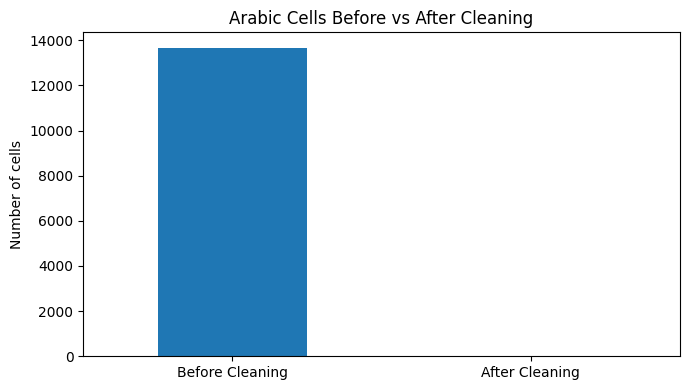

In [21]:

arabic_comparison = pd.Series({
    "Before Cleaning": sum(
        count_arabic_cells(df)
        for df in old_book.values()
    ),
    "After Cleaning": sum(
        count_arabic_cells(df)
        for df in new_book.values()
    ),
})

ax = arabic_comparison.plot(
    kind="bar",
    figsize=(7, 4),
    title="Arabic Cells Before vs After Cleaning"
)

ax.set_ylabel("Number of cells")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

|---|---|

**Profiling → Cleaning → Standardization → Translation → Column Selection → Missing Value Handling → Enrichment → Validation**